# Предобработка ЭЭГ, проверка гипотез, обучение и тюнинг моделей, сохранение финальных весов и модели в model

### Назначение: 
Предобработка сигнала ЭЭГ, проверка гипотез, обучение и тюнинг модели.
### Содержимое:
- Алгоритмы фильтрации и очистки сигнала (режекция артефактов, нормализация).
- Список и процесс генерации признаков (фичей) для обучения:
    - спектральная мощность по частотным диапазонам;
    - показатели функциональной связности;
    - параметры апериодического компонента спектра;
    - микросостояния;
    - поведенческие показатели выполнения таблиц Шульте.
- Обучение модели и тюнинг гиперпараметров.
### Обязательно: 
- разбиение на уровне испытуемых (leave-one-subject-out),
- исключение утечки данных.
- Сохранение модели в виде автономного модуля, который работает с исходными сырыми данными.
- обоснование выбора признаков и их клиническая/физиологическая значимость.
- Раздельная оценка качества модели с поведенческими признаками и без них.

**Референс на левом ухе.** Референсный электрод физически ближе к левым каналам (Fp1, T3, O1), чем к
правым (Fp2, T4, O2) — это системная инструментальная асимметрия, а не
физиология. Поэтому здесь, в отличие от более простого варианта
предобработки, добавлен обязательный шаг **re-reference на общий средний**
по 6 каналам, выполняемый **до** вычисления любых asymmetry- и
connectivity-признаков и до построения микросостояний (все три класса
признаков чувствительны к выбору референса).

### Импорты и конфигурация

In [1]:
import re
import time
import random
import warnings
from pathlib import Path
 
import numpy as np
import pandas as pd
from scipy import signal, stats as sps
 
import mne
 
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import (
    train_test_split, LeaveOneOut, GroupKFold, cross_val_predict, KFold, GridSearchCV,
)
from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score, precision_score, recall_score,
)
 
import joblib
 
warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
 
%matplotlib inline

In [2]:
DATA_DIR = Path("../data/neurodiagnostics-train")  # подставьте свой путь
OUT_DIR = Path("results")
OUT_DIR.mkdir(exist_ok=True)
MODULE_DIR = Path("deploy")
MODULE_DIR.mkdir(exist_ok=True)
 
# Каналы гарнитуры NeuroPlay-6C, порядок в файле не алфавитный — обращаемся по меткам (п. 3.2 ТЗ)
CHANNELS = ["Fp1", "Fp2", "T3", "T4", "O1", "O2"]
 
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}
 
ASYM_PAIRS = {"Fp": ("Fp1", "Fp2"), "T": ("T3", "T4"), "O": ("O1", "O2")}
CONN_PAIRS = [("Fp1", "Fp2"), ("T3", "T4"), ("O1", "O2"),
              ("Fp1", "T3"), ("T3", "O1"), ("Fp2", "T4"), ("T4", "O2")]
CONN_BANDS = ("theta", "alpha", "beta")
 
CI = {ch: i for i, ch in enumerate(CHANNELS)}
 
N_MICROSTATES = 4
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

In [3]:
def classify_file(stem: str):
    if re.search(r"(?:^|[_\-\s])(п|p|rest|покой)$", stem, re.I):
        return "rest"
    m = re.search(r"(?:^|[_\-\s])(\d+)$", stem)
    return f"task_{m.group(1)}" if m else "unknown"


 
def get_age(group_name: str, subj_name: str):
    if not group_name.lower().startswith("норм"):
        return None
    m = re.search(r"_(\\d+)$", subj_name)
    return int(m.group(1)) if m else None

In [4]:
mne.set_log_level("ERROR")  # чтобы не заваливало вывод служебными сообщениями

rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue
        for f in sorted(subj_dir.glob("*.edf")):
            kind = classify_file(f.stem)
            row = dict(group=group_dir.name, subject=subj_dir.name, file=f.name, kind=kind)
            try:
                raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
                raw.pick(CHANNELS)
                data = raw.get_data() * 1e6  # микровольты

                row["fs"] = raw.info["sfreq"]
                row["duration_s"] = raw.n_times / raw.info["sfreq"]
                row["amp_p99_uV"] = float(np.percentile(np.abs(data), 99))  # грубая оценка масштаба

                if kind == "rest":
                    # альфа-пик на затылочных каналах O1/O2
                    psd = raw.compute_psd(method="welch", fmin=1, fmax=30, picks=["O1", "O2"], verbose=False)
                    freqs = psd.freqs
                    p = psd.get_data().mean(axis=0)  # усредняем O1 и O2
                    alpha_mask = (freqs >= 7) & (freqs <= 13)
                    row["alpha_peak_hz"] = float(freqs[alpha_mask][p[alpha_mask].argmax()])
                    # есть ли реально выраженный пик (мощность в альфе заметно выше соседей)?
                    row["alpha_prominent"] = bool(p[alpha_mask].max() > 1.5 * np.median(p))

            except Exception as e:
                row["error"] = str(e)
            rows.append(row)

df = pd.DataFrame(rows)

print("Файлов не прочиталось:", df["error"].notna().sum() if "error" in df else 0)
if "error" in df and df["error"].notna().any():
    print(df[df["error"].notna()][["group", "subject", "file", "error"]])

print("\n--- Частоты дискретизации ---")
print(df["fs"].value_counts())

print("\n--- Длительности по типу файла (с) ---")
print(df.groupby(df["kind"].apply(lambda k: "rest" if k == "rest" else "task"))["duration_s"].describe().round(1))

print("\n--- Масштаб амплитуды (99-й перцентиль, мкВ) ---")
print(df["amp_p99_uV"].describe().round(1))
print("По группам:")
print(df.groupby("group")["amp_p99_uV"].describe().round(1))

print("\n--- Альфа-пик в покое (O1/O2) ---")
rest = df[df["kind"] == "rest"]
print(rest["alpha_peak_hz"].describe().round(2))
print(f"Доля с выраженным пиком: {rest['alpha_prominent'].mean():.0%}")
print(rest.groupby("group")["alpha_prominent"].mean().astype(float).round(2))


Файлов не прочиталось: 5
             group subject     file                   error
930  Соматоформные   XCFU5  T-1.edf  Bad EDF file provided.
931  Соматоформные   XCFU5  T-2.edf  Bad EDF file provided.
932  Соматоформные   XCFU5  T-3.edf  Bad EDF file provided.
933  Соматоформные   XCFU5  T-4.edf  Bad EDF file provided.
934  Соматоформные   XCFU5  T-5.edf  Bad EDF file provided.

--- Частоты дискретизации ---
fs
125.0    783
126.0     58
124.0     52
127.0     51
123.0     47
Name: count, dtype: int64

--- Длительности по типу файла (с) ---
      count  mean   std   min   25%   50%   75%    max
kind                                                  
rest  166.0  62.1   9.4  32.0  61.0  61.0  62.0  121.0
task  825.0  47.5  17.0   1.0  36.0  44.0  53.0  142.0

--- Масштаб амплитуды (99-й перцентиль, мкВ) ---
count      991.0
mean       604.4
std       1556.1
min         14.6
25%         53.0
50%         84.0
75%        349.8
max      32767.0
Name: amp_p99_uV, dtype: float64
По группам:

### Проверка усиления сиганала по каналам относительно других

По итогам консультации: канал T3 систематически усилен примерно в 2.9 раза
относительно остальных пяти каналов — это **калибровочная константа
гарнитуры**, а не шум отдельной записи, поэтому её нужно вычесть
математически (умножить сигнал на `1/2.9`), а не лечить интерполяцией или
выбрасыванием канала.

Делаем это в два шага: сначала **проверяем сами**, что коэффициент
действительно устойчив и не является случайностью одной подвыборки
(иначе можно "подправить" реальный сигнал), затем зашиваем поправку в
`preprocess_raw` как первый шаг — **до** детекции плохих каналов, потому
что усиленный T3 иначе искажает z-оценку остальных каналов (раздел 2,
`detect_bad_channels` считает z относительно среднего/СКО по всем 6
каналам, и вздутый T3 сдвигает эту статистику для всех).

In [5]:
def estimate_channel_gain_ratio(path, ref_channels=None):
    """Отношение СКО T3 к медиане СКО остальных каналов на одном файле
    (после базового bandpass, чтобы не ловить чистый дрейф)."""
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    raw.pick(CHANNELS)
    raw.filter(1, 40, method="iir", verbose=False)
    data = raw.get_data() * 1e6
    std_per_ch = data.std(axis=1)
    others = [s for ch, s in zip(CHANNELS, std_per_ch) if ch != "T3"]
    return std_per_ch[CI["T3"]] / np.median(others)


random.seed(3)
gain_sample = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    subj_dirs = [d for d in group_dir.iterdir() if d.is_dir()]
    for subj_dir in random.sample(subj_dirs, min(20, len(subj_dirs))):
        rest_f = next((f for f in subj_dir.glob("*.edf") if classify_file(f.stem) == "rest"), None)
        if rest_f is None:
            continue
        try:
            gain_sample.append(dict(group=group_dir.name, subject=subj_dir.name,
                                     ratio=estimate_channel_gain_ratio(rest_f)))
        except Exception:
            pass

gain_df = pd.DataFrame(gain_sample)
print(f"Медиана отношения T3/остальные: {gain_df['ratio'].median():.2f}")
print(f"IQR: [{gain_df['ratio'].quantile(0.25):.2f}, {gain_df['ratio'].quantile(0.75):.2f}]")
print(gain_df.groupby("group")["ratio"].median())

Медиана отношения T3/остальные: 1.17
IQR: [0.77, 3.00]
group
Норма            3.007202
ПТСР             0.907895
Соматоформные    1.181352
Name: ratio, dtype: float64


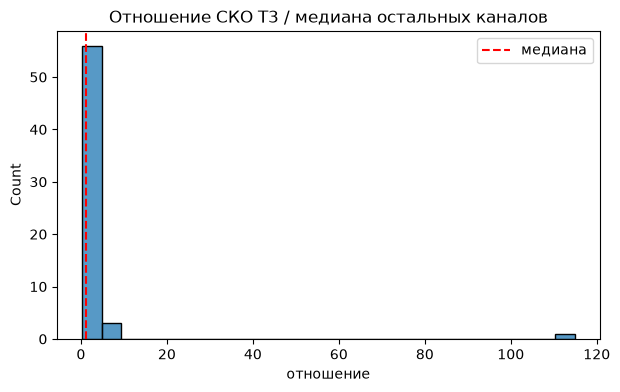

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(gain_df["ratio"], bins=25)
plt.axvline(gain_df["ratio"].median(), color="red", ls="--", label="медиана")
plt.title("Отношение СКО T3 / медиана остальных каналов")
plt.xlabel("отношение")
plt.legend()
plt.show()

### Итоги
- Объективно распределение не идеально узкое, есть некоторый разброс, значит, это не единая аппаратная поправка, а что-то ещё (например, контакт-зависимая проблема у части испытуемых) — тогда фиксированный множитель для всех — неверное  решение, нужно детектировать и чинить (или интерполировать) по каждой записи отдельно, как обычный плохой канал.

In [7]:
def calculate_channel_gain_ratios(
    raw,
    target_channels=("T3",),
):
    """
    Считает отношение СКО каждого target-канала
    к медиане СКО остальных каналов.

    raw должен быть уже отфильтрован.
    """

    data = raw.get_data() * 1e6
    std_per_ch = data.std(axis=1)

    channel_names = raw.ch_names
    result = {}

    for target in target_channels:
        if target not in channel_names:
            continue

        target_idx = channel_names.index(target)

        others = [
            std
            for ch, std in zip(
                channel_names,
                std_per_ch,
            )
            if ch != target
        ]

        if not others:
            result[target] = np.nan
            continue

        result[target] = (
            std_per_ch[target_idx]
            / np.median(others)
        )

    return result

 ### Предобработка сигнала

Порядок шагов:
 
1. **Монтаж** (нужен для интерполяции).
2. **Детекция плохих каналов** — по сырым данным, до фильтрации.
3. **Интерполяция** плохих каналов (если их не больше `max_bad_channels`).
4. **Полосовой фильтр** 1–40 Гц.
5. **Notch-фильтр** 50 Гц.
6. **Re-reference на общий средний (CAR)** — компенсация смещённого влево
   референса (левое ухо). Делается **до** ICA: ICA не портится от смены
   референса, а корреляция Fp1/Fp2 с глазными артефактами (шаг 7) работает
   на переприведённых к среднему каналах так же надёжно.
7. **ICA** — автоматическое удаление глазодвигательных компонент
   (find_bads_eog по Fp1/Fp2 как псевдо-EOG).
 
Отбраковка шумных 2-секундных окон (раздел 3) — независимая вторая линия
защиты от резидуальных артефактов.

In [8]:
MONTAGE = mne.channels.make_standard_montage("standard_1020")
 
 
def set_montage_safe(raw):
    raw = raw.copy()
    raw.set_montage(MONTAGE, on_missing="warn", match_case=False)
    return raw
 

def detect_bad_channels(
    raw,
    flat_thresh_uv=0.5,
    noisy_z_thresh=4.0,
    channel_gain_ratios=None,
    gain_ratio_min=0.5,
    gain_ratio_max=2.0,
):
    """
    Находит:
    1. плоские каналы;
    2. аномально шумные каналы;
    3. каналы с необычным отношением СКО к медиане остальных.

    channel_gain_ratios:
        словарь, например {"T3": ratio}.
        Если None, дополнительная проверка не используется.
    """

    data = raw.get_data() * 1e6
    std_per_ch = data.std(axis=1)

    channel_names = raw.ch_names
    # 1. Почти плоские каналы
    flat = std_per_ch < flat_thresh_uv
    # 2. Аномально шумные/тихие каналы относительно остальных
    log_std = np.log10(
        std_per_ch + 1e-9
    )
    z = (
        log_std - log_std.mean()
    ) / (
        log_std.std() + 1e-9
    )
    noisy = np.abs(z) > noisy_z_thresh

    # 3. Отдельная проверка отношения СКО к остальным каналам
    gain_outlier = np.zeros(
        len(channel_names),
        dtype=bool,
    )
    gain_ratio_log = {}

    if channel_gain_ratios is not None:
        for ch, ratio in channel_gain_ratios.items():
            if ch not in channel_names:
                continue

            gain_ratio_log[ch] = ratio

            is_outlier = (
                ratio < gain_ratio_min
                or ratio > gain_ratio_max
            )

            idx = channel_names.index(ch)
            gain_outlier[idx] = is_outlier

    bad_mask = (
        flat
        | noisy
        | gain_outlier
    )

    bad_names = [
        ch
        for ch, is_bad in zip(
            channel_names,
            bad_mask,
        )
        if is_bad
    ]

    details = {
        "std_uv": dict(
            zip(
                channel_names,
                std_per_ch,
            )
        ),
        "z_score": dict(
            zip(
                channel_names,
                z,
            )
        ),
        "gain_ratio": gain_ratio_log,
    }

    return bad_names, details


In [9]:
def preprocess_raw(
    raw,
    l_freq=1.0,
    h_freq=40.0,
    notch_freq=50.0,
    n_ica_components=5,
    eog_ch=("Fp1", "Fp2"),
    eog_corr_thresh=0.4,
    max_bad_channels=2,
    min_ica_duration_s=15.0,
    t3_ratio_min=0.5,              # ДОБАВЛЕНО
    t3_ratio_max=2.0,              # ДОБАВЛЕНО
    mark_t3_bad=False,             # ДОБАВЛЕНО
    verbose=False,
):
    """
    Полная предобработка одного Raw:

    1. Установка монтажа.
    2. Предварительный band-pass.
    3. Проверка относительной амплитуды T3.
    4. Поиск плохих каналов.
    5. Интерполяция плохих каналов.
    6. Notch-фильтр.
    7. Average reference / CAR.
    8. ICA.

    mark_t3_bad=False:
        только записывает подозрительный T3 в лог.

    mark_t3_bad=True:
        добавляет T3 в список плохих каналов
        для последующей интерполяции.
    """

    log = {
        "bad_channels": [],
        "n_bad_channels": 0,

        "t3_gain_ratio": np.nan,       # ДОБАВЛЕНО
        "t3_gain_suspicious": False,   # ДОБАВЛЕНО
        "t3_marked_bad": False,       # ДОБАВЛЕНО

        "ica_fit_ok": False,
        "ica_applied": False,
        "ica_skipped": False,
        "ica_error": False,
        "ica_skip_reason": None,

        "ica_n_components": 0,
        "ica_n_eog_candidates": 0,

        "n_ica_excluded": 0,
        "ica_excluded_idx": [],

        "referenced": False,
        "duration_s": None,
        "n_channels": None,
        "notes": [],
    }

    raw = raw.copy()
    raw.resample(125.0) # добавлено, чтобы избежать утечки по признаку sfreq

    duration_s = (
        raw.n_times
        / raw.info["sfreq"]
    )

    log["duration_s"] = duration_s
    log["n_channels"] = len(raw.ch_names)

    # 1. Монтаж
    try:
        raw = set_montage_safe(raw)

    except Exception as e:
        log["notes"].append(
            f"montage error: {e}"
        )

    # 2. Предварительный band-pass
    # ДОБАВЛЕНО:
    # T3 проверяется после фильтра 1–40 Гц,
    # чтобы не учитывать медленный дрейф.
    try:
        raw.filter(
            l_freq=l_freq,
            h_freq=h_freq,
            method="iir",
            verbose=verbose,
        )

    except Exception as e:
        log["notes"].append(
            f"band-pass filter error: {e}"
        )

    # 3. Проверка относительной амплитуды T3
    # ДОБАВЛЕНО:
    try:
        t3_ratios = calculate_channel_gain_ratios(
            raw,
            target_channels=("T3",),
        )

        t3_ratio = t3_ratios.get(
            "T3",
            np.nan,
        )

        log["t3_gain_ratio"] = t3_ratio

        if np.isfinite(t3_ratio):
            if (
                t3_ratio < t3_ratio_min
                or t3_ratio > t3_ratio_max
            ):
                log["t3_gain_suspicious"] = True

                log["notes"].append(
                    f"T3 suspicious gain ratio: "
                    f"{t3_ratio:.3f}"
                )

                # По умолчанию T3 НЕ объявляется плохим.
                # Это включается только явно:
                if mark_t3_bad:
                    raw.info["bads"] = ["T3"]
                    log["t3_marked_bad"] = True

    except Exception as e:
        log["notes"].append(
            f"T3 gain-ratio error: {e}"
        )

    # 4. Поиск плохих каналов
    try:
        bad_ch, _ = detect_bad_channels(raw)

        # ДОБАВЛЕНО:
        # если mark_t3_bad=True, объединяем
        # автоматические плохие каналы и T3
        if (
            mark_t3_bad
            and log["t3_marked_bad"]
            and "T3" not in bad_ch
        ):
            bad_ch.append("T3")

        bad_ch = sorted(set(bad_ch))

        log["bad_channels"] = bad_ch
        log["n_bad_channels"] = len(bad_ch)

        if len(bad_ch) > max_bad_channels:
            log["notes"].append(
                f"too many bad channels ({len(bad_ch)}), "
                "skipping interpolation"
            )

        elif bad_ch:
            raw.info["bads"] = bad_ch

            raw.interpolate_bads(
                reset_bads=True,
                verbose=verbose,
            )

    except Exception as e:
        log["notes"].append(
            f"bad-channel processing error: {e}"
        )

    # 5. Notch-фильтр
    if duration_s > 2.0:
        try:
            raw.notch_filter(
                freqs=notch_freq,
                method="fir",
                verbose=verbose,
            )

        except Exception as e:
            log["notes"].append(
                f"notch filter error: {e}"
            )

    else:
        log["notes"].append(
            f"notch skipped: "
            f"duration={duration_s:.2f}s <= 2s"
        )

    # 6. Average reference / CAR
    try:
        raw.set_eeg_reference(
            ref_channels="average",
            projection=False,
            verbose=verbose,
        )

        log["referenced"] = True

    except Exception as e:
        log["notes"].append(
            f"re-reference error: {e}"
        )

    # 7. ICA
    n_comp = min(
        n_ica_components,
        len(raw.ch_names) - 1,
    )

    log["ica_n_components"] = n_comp

    if n_comp < 2:
        log["ica_skipped"] = True
        log["ica_skip_reason"] = (
            f"too few channels for ICA: "
            f"{len(raw.ch_names)} channels"
        )
        log["notes"].append(
            log["ica_skip_reason"]
        )
        return raw, log

    if duration_s < min_ica_duration_s:
        log["ica_skipped"] = True
        log["ica_skip_reason"] = (
            f"recording too short: "
            f"{duration_s:.2f}s < "
            f"{min_ica_duration_s:.2f}s"
        )
        log["notes"].append(
            log["ica_skip_reason"]
        )
        return raw, log

    try:
        ica = mne.preprocessing.ICA(
            n_components=n_comp,
            random_state=RANDOM_STATE,
            max_iter="auto",
            verbose=verbose,
        )

        ica.fit(
            raw,
            verbose=verbose,
        )

        log["ica_fit_ok"] = True

        eog_idx = []

        available_eog_ch = [
            ch
            for ch in eog_ch
            if ch in raw.ch_names
            and ch not in raw.info["bads"]
        ]

        if not available_eog_ch:
            log["notes"].append(
                "ICA fitted, but no valid "
                "EOG channels available"
            )

        for ch in available_eog_ch:
            idx, _ = ica.find_bads_eog(
                raw,
                ch_name=ch,
                threshold=eog_corr_thresh,
                verbose=verbose,
            )
            eog_idx.extend(idx)

        eog_idx = sorted(set(eog_idx))

        log["ica_n_eog_candidates"] = len(eog_idx)

        if len(eog_idx) > n_comp // 2:
            log["notes"].append(
                "too many suspicious ICA components, "
                "ICA was fitted but not applied"
            )

        else:
            ica.exclude = eog_idx

            ica.apply(
                raw,
                verbose=verbose,
            )

            log["ica_applied"] = True
            log["n_ica_excluded"] = len(eog_idx)
            log["ica_excluded_idx"] = eog_idx

    except Exception as e:
        log["ica_error"] = True
        log["notes"].append(
            f"ICA error: {e}"
        )

    return raw, log

### Проверка на одном файле: до/после (включая эффект re-reference)

{'bad_channels': [], 'n_bad_channels': 0, 't3_gain_ratio': np.float64(2.2044025789170036), 't3_gain_suspicious': True, 't3_marked_bad': False, 'ica_fit_ok': True, 'ica_applied': False, 'ica_skipped': False, 'ica_error': False, 'ica_skip_reason': None, 'ica_n_components': 5, 'ica_n_eog_candidates': 4, 'n_ica_excluded': 0, 'ica_excluded_idx': [], 'referenced': True, 'duration_s': np.float64(63.0), 'n_channels': 6, 'notes': ['T3 suspicious gain ratio: 2.204', 'too many suspicious ICA components, ICA was fitted but not applied']}


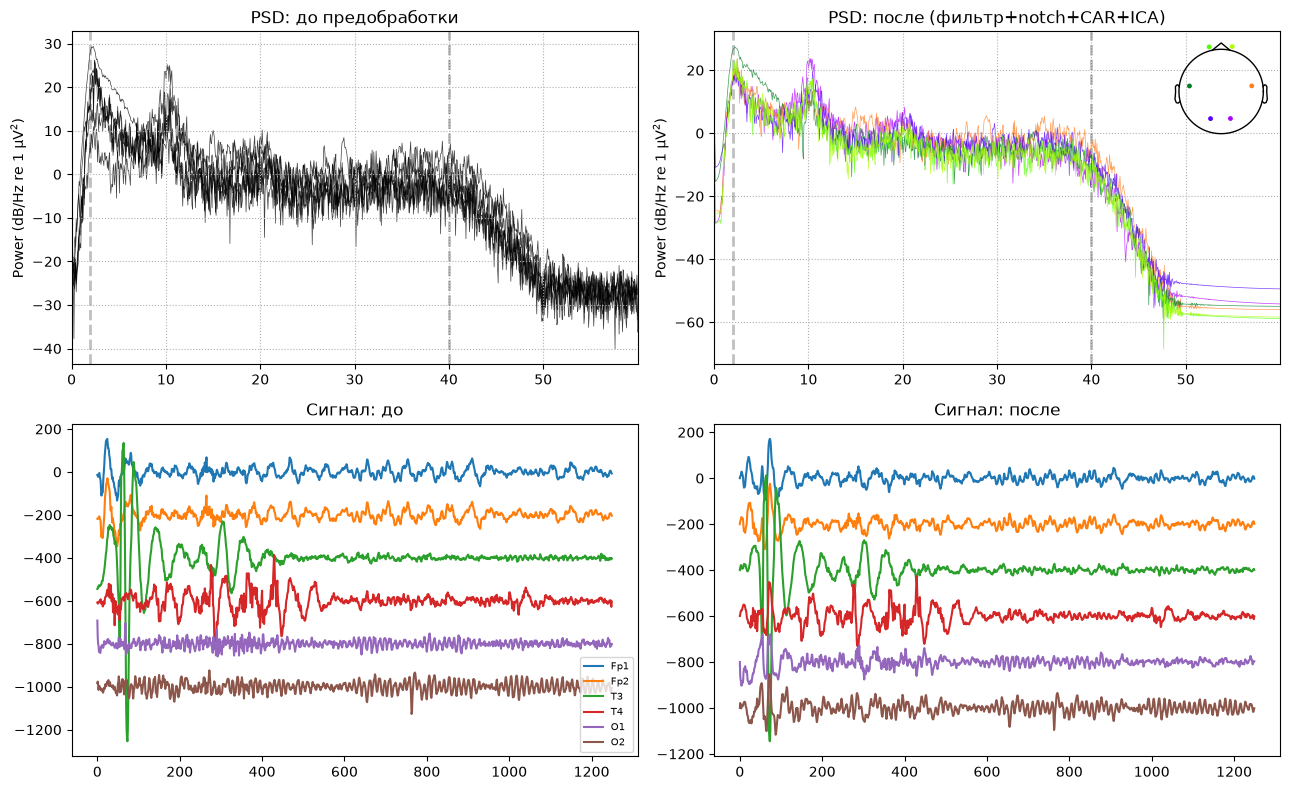

In [10]:
example_rest = DATA_DIR / "Норма" / "КС010_19" / "T-П.edf"
 
raw_check = mne.io.read_raw_edf(example_rest, preload=True, verbose=False)
raw_check.pick(CHANNELS)
raw_clean_demo, prep_log_demo = preprocess_raw(raw_check)
print(prep_log_demo)
 
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
raw_check.compute_psd(fmax=60).plot(axes=axes[0, 0], show=False)
axes[0, 0].set_title("PSD: до предобработки")
raw_clean_demo.compute_psd(fmax=60).plot(axes=axes[0, 1], show=False)
axes[0, 1].set_title("PSD: после (фильтр+notch+CAR+ICA)")
 
fs_ = raw_check.info["sfreq"]
n_ = int(10 * fs_)
d0 = raw_check.get_data() * 1e6
d1 = raw_clean_demo.get_data() * 1e6
for i, ch in enumerate(CHANNELS):
    axes[1, 0].plot(d0[i, :n_] - i * 200, label=ch)
    axes[1, 1].plot(d1[i, :n_] - i * 200, label=ch)
axes[1, 0].set_title("Сигнал: до"); axes[1, 0].legend(fontsize=7)
axes[1, 1].set_title("Сигнал: после")
plt.tight_layout()
plt.show()

In [11]:
# проверка эффекта re-reference отдельно: сравниваем std по левым/правым каналам
# до и после CAR — асимметрия из-за референса должна уменьшиться
def hemisphere_std_ratio(data):
    left = data[[CI["Fp1"], CI["T3"], CI["O1"]]].std(axis=1).mean()
    right = data[[CI["Fp2"], CI["T4"], CI["O2"]]].std(axis=1).mean()
    return left / right
 
ratio_before = hemisphere_std_ratio(d0)
ratio_after = hemisphere_std_ratio(d1)
print(f"Отношение СКО левые/правые каналы: до CAR={ratio_before:.3f}, после={ratio_after:.3f}")
print("Ожидание: после re-reference отношение должно быть ближе к 1.0, чем до.")

Отношение СКО левые/правые каналы: до CAR=1.240, после=1.270
Ожидание: после re-reference отношение должно быть ближе к 1.0, чем до.


In [12]:
def calculate_metrics(data):
    left_std = (
        data[left_idx]
        .std(axis=1)
        .mean()
    )

    right_std = (
        data[right_idx]
        .std(axis=1)
        .mean()
    )

    ratio = left_std / right_std

    # Симметричная мера отклонения от равенства:
    # log(left / right)
    abs_log_ratio = abs(
        np.log(left_std / right_std)
    )

    return {
        "left_std": left_std,
        "right_std": right_std,
        "ratio": ratio,
        "abs_log_ratio": abs_log_ratio,
    }

def compare_rereference_effect(
    data_before,
    data_after,
    ci,
    tolerance=1e-6,
):
    """
    Сравнивает левую/правую асимметрию до и после CAR.

    data_before, data_after:
        NumPy-массивы формы (n_channels, n_times).

    ci:
        Словарь индексов каналов, например:
        CI["Fp1"], CI["T3"], CI["O1"].

    Возвращает словарь с метриками.
    """
    left_idx = [
        ci["Fp1"],
        ci["T3"],
        ci["O1"],
    ]

    right_idx = [
        ci["Fp2"],
        ci["T4"],
        ci["O2"],
    ]
    before = calculate_metrics(data_before)
    after = calculate_metrics(data_after)

    asymmetry_delta = (
        after["abs_log_ratio"]
        - before["abs_log_ratio"]
    )

    if asymmetry_delta < -tolerance:
        result = "asymmetry_decreased"

    elif asymmetry_delta > tolerance:
        result = "asymmetry_increased"

    else:
        result = "unchanged"

    return {
        "ratio_before": before["ratio"],
        "ratio_after": after["ratio"],
        "abs_log_ratio_before": (
            before["abs_log_ratio"]
        ),
        "abs_log_ratio_after": (
            after["abs_log_ratio"]
        ),
        "asymmetry_delta": asymmetry_delta,
        "result": result,
    }

### Проверка всех файлов

In [13]:
prep_rows = []

for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue

    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue

        for f in sorted(subj_dir.glob("*.edf")):
            row = {
                "group": group_dir.name,
                "subject": subj_dir.name,
                "file": f.name,
                "path": str(f),

                "ok": False,
                "error": None,

                # ДОБАВЛЕНО:
                "duration_s": None,

                "bad_channels": "",
                "n_bad_channels": 0,

                "ica_fit_ok": False,
                "ica_skipped": False,
                "ica_error": False,
                "ica_skip_reason": None,

                "n_ica_excluded": 0,
                "ica_excluded_idx": "",

                "referenced": False,
                "notes": "",
            }

            try:
                raw = mne.io.read_raw_edf(
                    f,
                    preload=True,
                    verbose=False,
                )

                # ДОБАВЛЕНО:
                # фиксируем длительность сразу после чтения
                row["duration_s"] = (
                    raw.n_times / raw.info["sfreq"]
                )

                # Проверяем, что все нужные каналы присутствуют
                missing_channels = sorted(
                    set(CHANNELS) - set(raw.ch_names)
                )

                if missing_channels:
                    raise ValueError(
                        "Отсутствуют каналы: "
                        f"{missing_channels}"
                    )

                raw.pick(CHANNELS)

                raw_clean, log = preprocess_raw(
                    raw,
                    verbose=False,
                )

                notes = log.get(
                    "notes",
                    [],
                )

                row.update({
                    "ok": True,

                    # ДОБАВЛЕНО:
                    # берём duration из лога функции
                    "duration_s": log.get(
                        "duration_s",
                        row["duration_s"],
                    ),

                    "bad_channels": "; ".join(
                        map(
                            str,
                            log.get(
                                "bad_channels",
                                [],
                            ),
                        )
                    ),

                    "n_bad_channels": log.get(
                        "n_bad_channels",
                        0,
                    ),

                    "ica_fit_ok": log.get(
                        "ica_fit_ok",
                        False,
                    ),

                    "ica_skipped": log.get(
                        "ica_skipped",
                        False,
                    ),

                    "ica_error": log.get(
                        "ica_error",
                        False,
                    ),

                    "ica_skip_reason": log.get(
                        "ica_skip_reason",
                        None,
                    ),

                    "n_ica_excluded": log.get(
                        "n_ica_excluded",
                        0,
                    ),

                    "ica_excluded_idx": "; ".join(
                        map(
                            str,
                            log.get(
                                "ica_excluded_idx",
                                [],
                            ),
                        )
                    ),

                    "referenced": log.get(
                        "referenced",
                        False,
                    ),

                    "notes": "; ".join(
                        map(str, notes)
                    ),
                })

            except Exception as e:
                row["error"] = repr(e)

            prep_rows.append(row)


prep_df = pd.DataFrame(prep_rows)

prep_df.to_csv(
    "preprocess_log.csv",
    index=False,
    encoding="utf-8-sig",
)

print(f"Всего файлов: {len(prep_df)}")
print(
    "Упало с ошибкой:",
    (~prep_df["ok"]).sum(),
)
print(
    "ICA успешно обучена:",
    prep_df["ica_fit_ok"].sum(),
)
print(
    "ICA пропущена:",
    prep_df["ica_skipped"].sum(),
)
print(
    "ICA завершилась ошибкой:",
    prep_df["ica_error"].sum(),
)

Всего файлов: 996
Упало с ошибкой: 5
ICA успешно обучена: 989
ICA пропущена: 2
ICA завершилась ошибкой: 0


In [14]:
print(
    prep_df["duration_s"].describe()
)

count    991.000000
mean      49.981837
std       16.841078
min        1.000000
25%       38.000000
50%       48.000000
75%       60.000000
max      142.000000
Name: duration_s, dtype: float64


In [15]:
print(
    "Короче 2 секунд:",
    (prep_df["duration_s"] < 2).sum(),
)

print(
    "Короче 5 секунд:",
    (prep_df["duration_s"] < 5).sum(),
)

print(
    "Короче 10 секунд:",
    (prep_df["duration_s"] < 10).sum(),
)

print(
    "Короче 15 секунд:",
    (prep_df["duration_s"] < 15).sum(),
)

Короче 2 секунд: 1
Короче 5 секунд: 1
Короче 10 секунд: 2
Короче 15 секунд: 2


In [16]:
duration_by_group = (
    prep_df
    .groupby("group")["duration_s"]
    .describe()
)

display(duration_by_group)

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Норма,402.0,47.042289,12.184807,17.0,36.25,46.5,53.00,133.0
ПТСР,150.0,60.873333,22.209889,8.0,46.00,59.0,69.75,123.0
Соматоформные,439.0,48.952164,16.962085,1.0,37.00,46.0,60.00,142.0


In [17]:
summary_df = (
    prep_df
    .groupby("group")
    .agg(
        n_files=("file", "size"),
        n_ok=("ok", "sum"),
        n_failed=("ok", lambda x: (~x).sum()),
        mean_duration_s=("duration_s", "mean"),
        median_duration_s=("duration_s", "median"),
        n_ica_fit=("ica_fit_ok", "sum"),
        n_ica_skipped=("ica_skipped", "sum"),
        n_ica_errors=("ica_error", "sum"),
        mean_ica_excluded=("n_ica_excluded", "mean"),
        max_ica_excluded=("n_ica_excluded", "max"),
        n_referenced=("referenced", "sum"),
    )
)

display(summary_df)

,n_files,n_ok,n_failed,mean_duration_s,median_duration_s,n_ica_fit,n_ica_skipped,n_ica_errors,mean_ica_excluded,max_ica_excluded,n_referenced
group,,,,,,,,,,,
Норма,402,402,0,47.042289,46.5,402,0,0,0.0,0,402
ПТСР,150,150,0,60.873333,59.0,149,1,0,0.0,0,150
Соматоформные,444,439,5,48.952164,46.0,438,1,0,0.0,0,439


In [18]:
skip_reasons = (
    prep_df.loc[
        prep_df["ica_skipped"],
        "ica_skip_reason",
    ]
    .value_counts(dropna=False)
)

display(skip_reasons)

ica_skip_reason
recording too short: 8.00s < 15.00s    1
recording too short: 1.00s < 15.00s    1
Name: count, dtype: int64

In [19]:
def classify_ica_status(row):
    if not row["ok"]:
        return "file_error"

    if row["ica_error"]:
        return "ica_error"

    if row["ica_skipped"]:
        return "ica_skipped"

    if row["ica_fit_ok"]:
        return "ica_fit_ok"

    return "unknown"


prep_df["ica_status"] = prep_df.apply(
    classify_ica_status,
    axis=1,
)

print(
    prep_df["ica_status"]
    .value_counts()
)

ica_status
ica_fit_ok     989
file_error       5
ica_skipped      2
Name: count, dtype: int64


In [20]:
failed_df = prep_df.loc[
    ~prep_df["ok"],
    [
        "group",
        "subject",
        "file",
        "duration_s",
        "error",
    ],
]

display(failed_df)

,group,subject,file,duration_s,error
930,Соматоформные,XCFU5,T-1.edf,NaN,ValueError('Bad EDF file provided.')
931,Соматоформные,XCFU5,T-2.edf,NaN,ValueError('Bad EDF file provided.')
932,Соматоформные,XCFU5,T-3.edf,NaN,ValueError('Bad EDF file provided.')
933,Соматоформные,XCFU5,T-4.edf,NaN,ValueError('Bad EDF file provided.')
934,Соматоформные,XCFU5,T-5.edf,NaN,ValueError('Bad EDF file provided.')


In [21]:
display(
    prep_df[
        [
            "group",
            "subject",
            "file",
            "duration_s",
            "ok",
            "ica_fit_ok",
            "ica_skipped",
            "ica_error",
            "n_ica_excluded",
            "ica_skip_reason",
            "notes",
            "error",
        ]
    ].head(20)
)

,group,subject,file,duration_s,ok,ica_fit_ok,ica_skipped,ica_error,n_ica_excluded,ica_skip_reason,notes,error
0,Норма,КС010_19,T-1.edf,63.0,True,True,False,False,0,None,T3 suspicious gain ratio: 3.327; too many susp...,None
1,Норма,КС010_19,T-2.edf,44.0,True,True,False,False,0,None,T3 suspicious gain ratio: 2.621; too many susp...,None
2,Норма,КС010_19,T-3.edf,50.0,True,True,False,False,0,None,"too many suspicious ICA components, ICA was fi...",None
3,Норма,КС010_19,T-4.edf,33.0,True,True,False,False,0,None,T3 suspicious gain ratio: 0.353; too many susp...,None
4,Норма,КС010_19,T-5.edf,50.0,True,True,False,False,0,None,T3 suspicious gain ratio: 0.345; too many susp...,None
5,Норма,КС010_19,T-П.edf,63.0,True,True,False,False,0,None,T3 suspicious gain ratio: 2.204; too many susp...,None
6,Норма,КС011_25,T-1.edf,60.0,True,True,False,False,0,None,T3 suspicious gain ratio: 2.034; too many susp...,None
7,Норма,КС011_25,T-2.edf,54.0,True,True,False,False,0,None,"too many suspicious ICA components, ICA was fi...",None
8,Норма,КС011_25,T-3.edf,60.0,True,True,False,False,0,None,"too many suspicious ICA components, ICA was fi...",None
9,Норма,КС011_25,T-4.edf,52.0,True,True,False,False,0,None,"too many suspicious ICA components, ICA was fi...",None


In [22]:
CI = {ch: i for i, ch in enumerate(CHANNELS)}
results = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue
        for f in sorted(subj_dir.glob("*.edf")):
            try:
                raw_check = mne.io.read_raw_edf(f, preload=True, verbose=False)
                raw_check.pick(CHANNELS)
                raw_clean_demo, prep_log_demo = preprocess_raw(raw_check)

                d0 = raw_check.get_data()
                d1 = raw_clean_demo.get_data()

                ratio_before = hemisphere_std_ratio(d0)
                ratio_after = hemisphere_std_ratio(d1)

                results.append(dict(group=group_dir.name, subject=subj_dir.name, file=f.name,
                                     ratio_before=ratio_before, ratio_after=ratio_after,
                                     closer_to_1=abs(ratio_after - 1) < abs(ratio_before - 1)))
            except Exception as e:
                results.append(dict(group=group_dir.name, subject=subj_dir.name, file=f.name,
                                     error=str(e)))

ratio_df = pd.DataFrame(results)
print(f"Всего файлов: {len(ratio_df)}")
print(f"Стало ближе к 1: {(ratio_df['closer_to_1'] == True).sum()}")
print(f"Стало дальше от 1: {(ratio_df['closer_to_1'] == False).sum()}")
print(f"Ошибок: {ratio_df['error'].notna().sum() if 'error' in ratio_df else 0}")

ratio_df.to_csv("hemisphere_ratio_check.csv", index=False)
ratio_df


Всего файлов: 996
Стало ближе к 1: 688
Стало дальше от 1: 303
Ошибок: 5


,group,subject,file,ratio_before,ratio_after,closer_to_1,error
0,Норма,КС010_19,T-1.edf,1.554747,1.436823,True,NaN
1,Норма,КС010_19,T-2.edf,1.534356,1.451570,True,NaN
2,Норма,КС010_19,T-3.edf,1.323724,1.406106,False,NaN
3,Норма,КС010_19,T-4.edf,1.127043,1.168591,False,NaN
4,Норма,КС010_19,T-5.edf,1.133619,1.203284,False,NaN
...,...,...,...,...,...,...,...
991,Соматоформные,ZXCV1,T-2.edf,0.980723,1.093994,False,NaN
992,Соматоформные,ZXCV1,T-3.edf,0.885508,0.907012,True,NaN
993,Соматоформные,ZXCV1,T-4.edf,0.918086,0.967666,True,NaN
994,Соматоформные,ZXCV1,T-5.edf,0.903622,0.920951,True,NaN


In [23]:
reref_rows = []

for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue

    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue

        for f in sorted(subj_dir.glob("*.edf")):
            row = {
                "group": group_dir.name,
                "subject": subj_dir.name,
                "file": f.name,
                "ok": False,
                "error": None,
                "ratio_before": np.nan,
                "ratio_after": np.nan,
                "abs_log_ratio_before": np.nan,
                "abs_log_ratio_after": np.nan,
                "asymmetry_delta": np.nan,
                "result": None,
            }

            try:
                raw = mne.io.read_raw_edf(
                    f,
                    preload=True,
                    verbose=False,
                )

                missing_channels = sorted(
                    set(CHANNELS) - set(raw.ch_names)
                )

                if missing_channels:
                    raise ValueError(
                        f"Отсутствуют каналы: "
                        f"{missing_channels}"
                    )

                raw.pick(CHANNELS)

                # Данные до preprocessing / CAR
                d0 = raw.get_data()

                # Применяем первую функцию
                raw_clean, log = preprocess_raw(
                    raw,
                    verbose=False,
                )

                # Данные после CAR
                d1 = raw_clean.get_data()

                result = compare_rereference_effect(
                    data_before=d0,
                    data_after=d1,
                    ci=CI,
                )

                row.update({
                    "ok": True,
                    "ratio_before": result[
                        "ratio_before"
                    ],
                    "ratio_after": result[
                        "ratio_after"
                    ],
                    "abs_log_ratio_before": result[
                        "abs_log_ratio_before"
                    ],
                    "abs_log_ratio_after": result[
                        "abs_log_ratio_after"
                    ],
                    "asymmetry_delta": result[
                        "asymmetry_delta"
                    ],
                    "result": result[
                        "result"
                    ],
                })

            except Exception as e:
                row["error"] = repr(e)

            reref_rows.append(row)


reref_df = pd.DataFrame(reref_rows)

reref_df.to_csv(
    "rereference_check.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    f"Всего файлов: {len(reref_df)}"
)

print(
    "Успешно проверено:",
    reref_df["ok"].sum(),
)

print(
    "Ошибок:",
    (~reref_df["ok"]).sum(),
)

print(
    reref_df["result"]
    .value_counts(dropna=False)
)

Всего файлов: 996
Успешно проверено: 0
Ошибок: 996
result
None    996
Name: count, dtype: int64


In [24]:
car_rows = []

for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue

    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir():
            continue

        for f in sorted(subj_dir.glob("*.edf")):
            try:
                raw = mne.io.read_raw_edf(
                    f,
                    preload=True,
                    verbose=False,
                )

                missing_channels = sorted(
                    set(CHANNELS) - set(raw.ch_names)
                )

                if missing_channels:
                    continue

                raw.pick(CHANNELS)

                raw_clean, log = preprocess_raw(
                    raw,
                    verbose=False,
                )

                data_after = raw_clean.get_data()
                mean_after = data_after.mean(axis=0)

                car_rows.append({
                    "group": group_dir.name,
                    "subject": subj_dir.name,
                    "file": f.name,
                    "mean_abs_after_car": np.mean(
                        np.abs(mean_after)
                    ),
                    "mean_rms_after_car": np.sqrt(
                        np.mean(mean_after ** 2)
                    ),
                })

            except Exception:
                continue


car_df = pd.DataFrame(car_rows)

print(
    car_df["mean_abs_after_car"].describe()
)

display(
    car_df
    .groupby("group")[
        [
            "mean_abs_after_car",
            "mean_rms_after_car",
        ]
    ]
    .describe()
)

count    9.910000e+02
mean     3.116557e-21
std      6.965470e-21
min      2.440397e-22
25%      6.007476e-22
50%      9.227205e-22
75%      1.999743e-21
max      1.288381e-19
Name: mean_abs_after_car, dtype: float64


mean_abs_after_car                                            \
                           count          mean           std           min   
group                                                                        
Норма                      402.0  7.819889e-22  3.469833e-22  2.440397e-22   
ПТСР                       150.0  1.092690e-21  7.725265e-22  3.745923e-22   
Соматоформные              439.0  5.945888e-21  9.742783e-21  3.290364e-22   

                                                                       \
                        25%           50%           75%           max   
group                                                                   
Норма          5.737142e-22  6.177725e-22  9.474532e-22  2.723603e-21   
ПТСР           6.150584e-22  8.192768e-22  1.180180e-21  4.888173e-21   
Соматоформные  8.628938e-22  2.549122e-21  7.009934e-21  1.288381e-19   

              mean_rms_after_car                                            \
                           count          mean           std           min   
group                                                                        
Норма                      402.0  1.260402e-21  7.730072e-22  3.608780e-22   
ПТСР                       150.0  2.722651e-21  3.142012e-21  5.451478e-22   
Соматоформные              439.0  2.312060e-20  3.118302e-20  5.543834e-22   

                                                                       
                        25%           50%           75%           max  
group                                                                  
Норма          8.336427e-22  9.096956e-22  1.474412e-21  6.674241e-21  
ПТСР           9.789716e-22  1.358056e-21  2.330561e-21  1.420219e-20  
Соматоформные  1.390997e-21  7.772176e-21  4.062939e-20  3.275949e-19

После average re-reference среднее абсолютное значение межканального среднего составило 
3.13
×
10
−
21
3.13×10
−21
 В, что указывает на практически нулевое остаточное среднее по EEG-каналам и подтверждает корректное применение CAR.

### Батч-проверка: падения, время работы, конфаундер артефактности по группам

In [25]:
random.seed(0)
sample_files = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    subj_dirs = [d for d in group_dir.iterdir() if d.is_dir()]
    for subj_dir in random.sample(subj_dirs, min(15, len(subj_dirs))):
        for f in subj_dir.glob("*.edf"):
            sample_files.append((group_dir.name, subj_dir.name, f))
 
diag_rows = []
for group, subj, f in sample_files:
    try:
        raw = mne.io.read_raw_edf(f, preload=True, verbose=False)
        raw.pick(CHANNELS)
        t0 = time.time()
        _, log = preprocess_raw(raw)
        elapsed = time.time() - t0
        diag_rows.append(dict(
            group=group, subject=subj, file=f.name, kind=classify_file(f.stem),
            n_bad_channels=log["n_bad_channels"], n_ica_excluded=log["n_ica_excluded"],
            ica_fit_ok=log["ica_fit_ok"], referenced=log["referenced"],
            notes="; ".join(log["notes"]), elapsed_s=elapsed,
        ))
    except Exception as e:
        diag_rows.append(dict(group=group, subject=subj, file=f.name, error=str(e)))
 
diag_df = pd.DataFrame(diag_rows)
print("Ошибок:", diag_df.get("error", pd.Series(dtype=object)).notna().sum(), "из", len(diag_df))
diag_df.describe(include="all")

Ошибок: 0 из 270


,group,subject,file,kind,n_bad_channels,n_ica_excluded,ica_fit_ok,referenced,notes,elapsed_s
count,270,270,270,270,270.0,270.0,270,270,270,270.000000
unique,3,45,6,6,NaN,NaN,2,1,109,NaN
top,Норма,КС024_20,T-2.edf,task_2,NaN,NaN,True,True,"too many suspicious ICA components, ICA was fi...",NaN
freq,90,6,45,45,NaN,NaN,269,270,159,NaN
mean,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.074246
std,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.086134
min,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.008480
25%,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.049984
50%,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.053982
75%,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.064591


In [27]:
rest_diag = diag_df[diag_df["kind"] == "rest"]
groups_ica = [g["n_ica_excluded"].dropna().values for _, g in rest_diag.groupby("group")]

# убираем пустые группы
groups_ica = [g for g in groups_ica if len(g) > 0]

all_vals = np.concatenate(groups_ica) if groups_ica else np.array([])

if len(groups_ica) < 2 or np.unique(all_vals).size < 2:
    print("Kruskal-Wallis пропущен: во всех группах одинаковые значения n_ica_excluded.")
    print(f"  значения: {np.unique(all_vals)}")
    p_val = np.nan
else:
    h_stat, p_val = sps.kruskal(*groups_ica)
    print(f"Kruskal-Wallis, n_ica_excluded между группами: H={h_stat:.2f}, p={p_val:.3f}")

Kruskal-Wallis пропущен: во всех группах одинаковые значения n_ica_excluded.
  значения: [0]


### Отбраковка окон

2-секундные окна, перекрытие 50%, робастная (медиана/MAD) z-оценка по RMS.

In [28]:
def clean_epochs(data, fs, win_s=2.0, z_thresh=4.0):
    L = int(win_s * fs)
    starts = np.arange(0, data.shape[1] - L + 1, L // 2)
    if len(starts) < 3:
        return None
    epochs = np.stack([data[:, s:s + L] for s in starts])
    rms = epochs.std(axis=2)
    med = np.median(rms, axis=0)
    mad = np.median(np.abs(rms - med), axis=0) * 1.4826 + 1e-12
    z = np.abs(rms - med) / mad
    keep = (z < z_thresh).all(axis=1)
    if keep.sum() < 3:
        keep = np.ones(len(starts), dtype=bool)
    return epochs[keep]

### Признаки: спектральная мощность и асимметрия

Относительная мощность по диапазонам (доля от суммарной мощности 1-40 Гц —
устойчива к неоднородности масштабирования EDF, п. 3.2 ТЗ) и
межполушарная асимметрия (лог правый − лог левый по Fp/T/O). Асимметрия
считается **на данных после CAR** (раздел 2) — иначе инструментальный
сдвиг из-за референса на левом ухе подмешался бы в знак и величину.
 
**Обоснование признаков:** относительная (не абсолютная) мощность выбрана
специально, чтобы не зависеть от неоднородного масштабирования между
записями. Асимметрия — самый воспроизводимый в литературе по ПТСР маркер
(связан с латерализацией эмоциональной регуляции), но требует чистого
референса, отсюда обязательность шага CAR выше.

In [29]:
def relative_band_power(epochs, fs, bands=BANDS):
    f, p = signal.welch(epochs, fs=fs, nperseg=epochs.shape[-1], axis=-1)
    p = np.median(p, axis=0)
    total = p[:, (f >= 1) & (f <= 40)].sum(axis=1, keepdims=True)
    out = {}
    for name, (lo, hi) in bands.items():
        mask = (f >= lo) & (f < hi)
        out[name] = p[:, mask].sum(axis=1) / total[:, 0]
    return out
 
 
def asymmetry_features(rp, bands=("theta", "alpha", "beta")):
    """log(правый) - log(левый). Положительное значение = справа активность выше."""
    out = {}
    for band in bands:
        logp = np.log10(rp[band] + 1e-12)
        for name, (left, right) in ASYM_PAIRS.items():
            out[f"asym_{band}_{name}"] = float(logp[CI[right]] - logp[CI[left]])
    return out

###  Признаки: апериодический компонент и альфа-пик

Наклон 1/f (exponent) — подгонка прямой в лог-лог координатах вне
альфа-диапазона (чтобы пик её не искажал), плюс высота и частота
альфа-пика относительно этой линии.
 
**Клиническая значимость:** более плоский наклон 1/f у литературы
связывается с повышенным отношением возбуждение/торможение в коре —
предполагаемый механизм гипервозбуждения при ПТСР. Подавленный альфа-пик
в покое с закрытыми глазами (Приложение 1: именно на этой минуте
альфа-ритм затылочных отведений максимален в норме) — классический маркер
неспособности перейти в состояние спокойного бодрствования.

In [30]:
def aperiodic_and_peak(epochs, fs, fit_range=(2, 30), alpha_range=(7, 13.5), exclude_alpha=(7, 14)):
    f, p = signal.welch(epochs, fs=fs, nperseg=epochs.shape[-1], axis=-1)
    p = np.median(p, axis=0)
 
    fit_mask = (f >= fit_range[0]) & (f <= fit_range[1]) & (power > 0)
    logf_fit = np.log10(f[fit_mask] + 1e-12)
 
    out = {}
    for i, ch in enumerate(CHANNELS):
        logp_fit = np.log10(p[i, fit_mask] + 1e-12)
        slope, intercept = np.polyfit(logf_fit, logp_fit, 1)
        exponent = -slope
 
        fit_line = intercept + slope * np.log10(f + 1e-12)
        resid = np.log10(p[i] + 1e-12) - fit_line
 
        alpha_mask = (f >= alpha_range[0]) & (f <= alpha_range[1])
        if alpha_mask.sum() > 0:
            local_idx = np.argmax(resid[alpha_mask])
            peak_freq = float(f[alpha_mask][local_idx])
            peak_height = float(resid[alpha_mask][local_idx])
            prominent = peak_height > 0.1
        else:
            peak_freq, peak_height, prominent = np.nan, np.nan, False
 
        out[f"{ch}__exponent"] = float(exponent)
        out[f"{ch}__alpha_peak_freq"] = peak_freq
        out[f"{ch}__alpha_peak_height"] = peak_height
        out[f"{ch}__alpha_prominent"] = bool(prominent)
    return out

### Признаки: функциональная связность

Мнимая когерентность (imaginary coherence) — в отличие от обычной
когерентности устойчива к эффектам общего референса и объёмной
проводимости (реальный сигнал, идущий "через" общий референс, даёт почти
нулевую фазовую задержку — мнимая часть его отфильтровывает). Это
дополнительная (после CAR) защита именно от того типа артефакта, который
даёт референс на левом ухе.
 
**Клиническая значимость:** межполушарная и лобно-височная связность —
маркер интеграции обработки эмоционально значимой/угрожающей информации;
нарушения связности между лобными и височными областями многократно
описаны при ПТСР.

In [31]:
def imaginary_coherence(epochs, fs, pairs=CONN_PAIRS, bands=CONN_BANDS):
    n_win, n_ch, L = epochs.shape
    window = np.hanning(L)
    X = np.fft.rfft(epochs * window, axis=-1)
    freqs = np.fft.rfftfreq(L, 1 / fs)
 
    out = {}
    for band in bands:
        lo, hi = BANDS[band]
        mask = (freqs >= lo) & (freqs < hi)
        for ch_a, ch_b in pairs:
            ia, ib = CI[ch_a], CI[ch_b]
            Xa = X[:, ia, :][:, mask]
            Xb = X[:, ib, :][:, mask]
            Sab = (Xa * np.conj(Xb)).mean(axis=0)
            Saa = (Xa * np.conj(Xa)).mean(axis=0).real
            Sbb = (Xb * np.conj(Xb)).mean(axis=0).real
            icoh = np.abs(Sab.imag) / np.sqrt(Saa * Sbb + 1e-12)
            out[f"conn_{band}_{ch_a}-{ch_b}"] = float(np.mean(icoh))
    return out

### Признаки: микросостояния (microstates)

Микросостояния — квазистабильные топографии электрического поля,
сменяющие друг друга каждые ~60-120 мс. Стандартный алгоритм: находим
пики глобальной мощности поля (GFP — по сути, "самые чистые" от шума
моменты), кластеризуем их топографии modified K-means с
полярностно-инвариантной метрикой (знак топографии в микросостояниях не
важен), затем "бэкфитим" получившиеся шаблоны на всю запись и считаем
длительность/встречаемость/долю времени для каждого состояния.
 
Если кластеризовать
топографии отдельно для каждого файла, состояние "A" у одного испытуемого
и "A" у другого могут оказаться совершенно разными паттернами — тогда
признаки `ms0_*`, `ms1_*` не сравнимы между людьми. Поэтому шаблоны
микросостояний обучаются **один раз на пуле файлов из всех трёх групп**
, а затем **фиксированно** применяются («бэкфит») к каждому
отдельному файлу— так состояния остаются одними и теми же
для всех испытуемых.
 
канонические 4 микросостояния (A/B/C/D)
обычно выделяются на полном 32+-канальном монтаже; на 6 каналах
пространственное разрешение намного ниже, и получившиеся кластеры скорее
всего не будут напрямую соответствовать классическим A/B/C/D из
литературы. Используем их как эмпирические, а не литературные,
состояния — интерпретация опирается на топографию самих шаблонов
(построенных в 7.1), а не на предполагаемое соответствие A/B/C/D.
 
**Клиническая значимость (в общем виде, требует проверки на своих
шаблонах):** изменённая встречаемость и длительность отдельных
микросостояний при ПТСР описывается в литературе как коррелят
нестабильности сетей выявления значимости стимулов (salience network) и
руминации/навязчивых мыслей.

### Обучение глобальных шаблонов микросостояний

In [32]:
def extract_gfp_peaks(data, min_distance_samples=1):
    """data: [каналы, время], уже CAR-референсировано. Возвращает индексы пиков GFP."""
    gfp = data.std(axis=0)
    peaks, _ = signal.find_peaks(gfp, distance=min_distance_samples)
    return peaks
 
 
def modified_kmeans_microstates(maps, n_states=N_MICROSTATES, n_runs=10, max_iter=200, seed=0):
    """maps: [n_пиков, каналы] — топографии в моменты пиков GFP (полярностно-инвариантная кластеризация)."""
    maps_norm = maps / (np.linalg.norm(maps, axis=1, keepdims=True) + 1e-12)
 
    best_gev, best_states = -np.inf, None
    for run in range(n_runs):
        rng = np.random.default_rng(seed + run)
        init_idx = rng.choice(len(maps_norm), n_states, replace=False)
        states = maps_norm[init_idx].copy()
 
        for _ in range(max_iter):
            corr = maps_norm @ states.T                     # [n_пиков, n_states]
            labels = np.argmax(np.abs(corr), axis=1)
 
            new_states = np.zeros_like(states)
            for k in range(n_states):
                members = maps_norm[labels == k]
                if len(members) == 0:
                    new_states[k] = states[k]
                    continue
                signs = np.sign(members @ states[k])
                signs[signs == 0] = 1
                aligned = members * signs[:, None]
                cov = aligned.T @ aligned
                eigvals, eigvecs = np.linalg.eigh(cov)
                new_states[k] = eigvecs[:, -1]               # доминантный собственный вектор
 
            if np.allclose(new_states, states, atol=1e-6):
                states = new_states
                break
            states = new_states
 
        corr = maps_norm @ states.T
        gev = float((np.max(corr ** 2, axis=1)).sum())
        if gev > best_gev:
            best_gev, best_states = gev, states
 
    return best_states, best_gev

In [33]:
def fit_global_microstate_templates(data_dir, n_subjects_per_group=15, seed=0):
    """Пул GFP-пиков из записей покоя по репрезентативной подвыборке из ВСЕХ групп
    (важно не смещать шаблоны в сторону одной группы) -> общие шаблоны микросостояний."""
    rng = random.Random(seed)
    pooled_maps = []
 
    for group_dir in sorted(Path(data_dir).iterdir()):
        if not group_dir.is_dir():
            continue
        subj_dirs = [d for d in group_dir.iterdir() if d.is_dir()]
        for subj_dir in rng.sample(subj_dirs, min(n_subjects_per_group, len(subj_dirs))):
            rest_f = next((f for f in subj_dir.glob("*.edf") if classify_file(f.stem) == "rest"), None)
            if rest_f is None:
                continue
            try:
                raw = mne.io.read_raw_edf(rest_f, preload=True, verbose=False)
                raw.pick(CHANNELS)
                raw, _ = preprocess_raw(raw)
                data = raw.get_data() * 1e6
                peaks = extract_gfp_peaks(data)
                if len(peaks) > 0:
                    pooled_maps.append(data[:, peaks].T)
            except Exception:
                continue
 
    all_maps = np.concatenate(pooled_maps, axis=0)
    print(f"Пиков GFP в пуле для обучения шаблонов: {all_maps.shape[0]} "
          f"(из {len(pooled_maps)} испытуемых)")
 
    templates, gev = modified_kmeans_microstates(all_maps, n_states=N_MICROSTATES)
    print(f"GEV (доля объяснённой дисперсии) на обучающем пуле: {gev / len(all_maps):.3f} на пик")
    return templates

In [34]:
# обучаем один раз, шаблоны фиксируются для всего последующего анализа
MS_TEMPLATES = fit_global_microstate_templates(DATA_DIR, n_subjects_per_group=15, seed=RANDOM_STATE)
np.save(OUT_DIR / "microstate_templates.npy", MS_TEMPLATES)

Пиков GFP в пуле для обучения шаблонов: 82615 (из 45 испытуемых)
GEV (доля объяснённой дисперсии) на обучающем пуле: 0.695 на пик


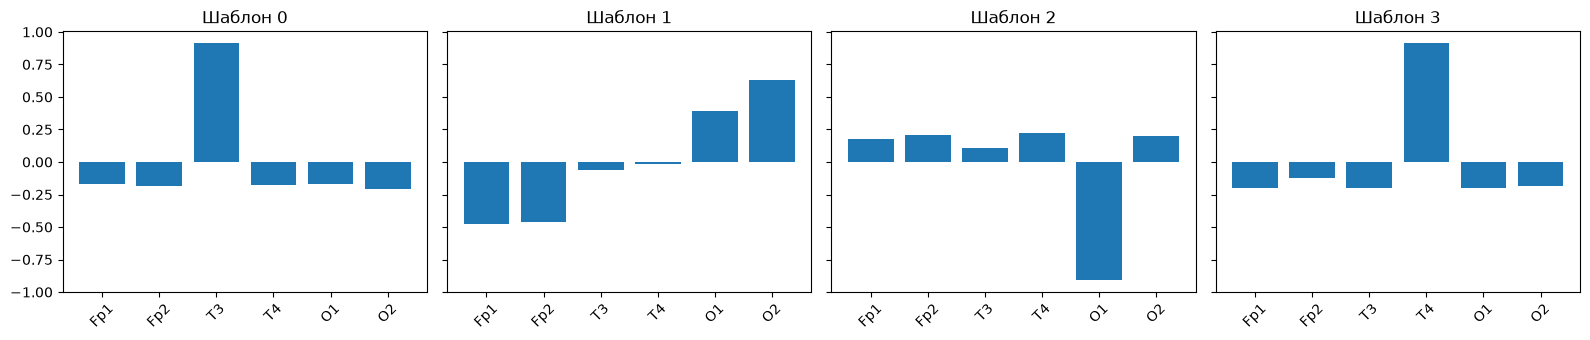

In [35]:
# визуализация шаблонов как псевдо-топографий (упрощённо: столбиковая диаграмма по 6 каналам,
# т.к. полноценный topomap на 6 разреженных точках малоинформативен)
fig, axes = plt.subplots(1, N_MICROSTATES, figsize=(4 * N_MICROSTATES, 3.5), sharey=True)
for k in range(N_MICROSTATES):
    axes[k].bar(CHANNELS, MS_TEMPLATES[k])
    axes[k].set_title(f"Шаблон {k}")
    axes[k].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [36]:
def backfit_microstates(data, templates):
    """data: [каналы, время], CAR-референсировано. Возвращает labels[время] — индекс состояния."""
    norm_data = data / (np.linalg.norm(data, axis=0, keepdims=True) + 1e-12)
    corr = templates @ norm_data                        # [n_states, время]
    labels = np.argmax(np.abs(corr), axis=0)
    return labels
 
 
def microstate_features(labels, fs, n_states=N_MICROSTATES):
    """Средняя длительность, частота встречаемости и доля времени по каждому состоянию."""
    feats = {}
    total_time = len(labels) / fs
    if total_time <= 0:
        return {f"ms{k}_{p}": np.nan for k in range(n_states)
                for p in ("occurrence_per_s", "coverage", "mean_dur_s")}
 
    change_idx = np.where(np.diff(labels) != 0)[0] + 1
    segments = np.split(labels, change_idx)
 
    for k in range(n_states):
        durations = [len(seg) / fs for seg in segments if len(seg) and seg[0] == k]
        feats[f"ms{k}_occurrence_per_s"] = len(durations) / total_time
        feats[f"ms{k}_coverage"] = float(sum(durations) / total_time) if durations else 0.0
        feats[f"ms{k}_mean_dur_s"] = float(np.mean(durations)) if durations else 0.0
    return feats


{'ms0_occurrence_per_s': 7.158730158730159, 'ms0_coverage': 0.13599999999999998, 'ms0_mean_dur_s': 0.018997782705099782, 'ms1_occurrence_per_s': 15.253968253968255, 'ms1_coverage': 0.5530158730158731, 'ms1_mean_dur_s': 0.03625390218522373, 'ms2_occurrence_per_s': 9.476190476190476, 'ms2_coverage': 0.1354920634920635, 'ms2_mean_dur_s': 0.014298157453936351, 'ms3_occurrence_per_s': 9.761904761904763, 'ms3_coverage': 0.1754920634920635, 'ms3_mean_dur_s': 0.017977235772357724}


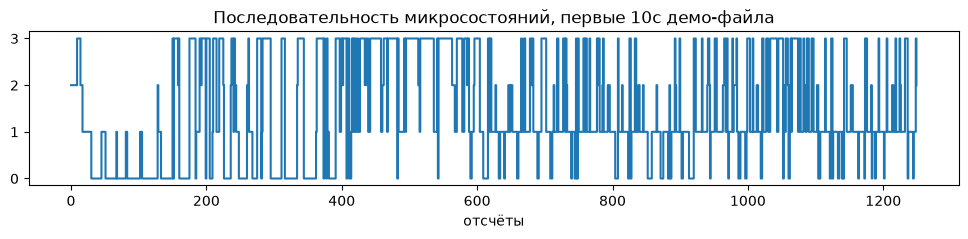

In [41]:
# проверка на демо-файле
raw_demo = mne.io.read_raw_edf(example_rest, preload=True, verbose=False)
raw_demo.pick(CHANNELS)
raw_demo_clean, _ = preprocess_raw(raw_demo)
data_demo = raw_demo_clean.get_data() * 1e6
labels_demo = backfit_microstates(data_demo, MS_TEMPLATES)
ms_feats_demo = microstate_features(labels_demo, raw_demo_clean.info["sfreq"])
print(ms_feats_demo)
 
plt.figure(figsize=(12, 2))
plt.plot(labels_demo[:int(10 * raw_demo_clean.info['sfreq'])], drawstyle="steps-post")
plt.yticks(range(N_MICROSTATES))
plt.title("Последовательность микросостояний, первые 10с демо-файла")
plt.xlabel("отсчёты")
plt.show()

по итогу мы не брали микросостояния как фичи, так как тесты с ними показывали хуже метрики

### Подготовка данных

Сырые .edf → предобработанные .fif (проверка gain-ratio по T3, ресемплинг до 125 Гц, фильтрация, интерполяция плохих каналов, перезадание референса, ICA — см. prep_v2.py). Показывает прогресс-бар tqdm по субъектам.


In [7]:
from pathlib import Path
import sys
import joblib
import pandas as pd
from sklearn.metrics import roc_auc_score
import subprocess

RAW_DIR = Path("../data/neurodiagnostics-train")
PREP_DIR = Path("../model/neurodiagnostics-train-prep-pipeline")
FEATURES_DIR = Path("../model/pipeline_features")
MODEL_EEG = Path("../model/pipeline_model_eeg.joblib")
MODEL_EEG_BEHAV = Path("../model/pipeline_model_eeg_behavioral.joblib")
LOSO_EEG_CSV = Path("../results/pipeline_loso_eeg.csv")
LOSO_EEG_BEHAV_CSV = Path("../results/pipeline_loso_eeg_behavioral.csv")
N_JOBS = 10

In [9]:
cmd = [sys.executable, "../model/pipeline_data_preparation.py", str(RAW_DIR), str(PREP_DIR)]
print("Запуск:", " ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print("=== STDERR ===")
    print(result.stderr)
    raise RuntimeError(f"pipeline_data_preparation.py упал с кодом {result.returncode}")

print("Готово. Файлы в", PREP_DIR)

Запуск: /home/veronika/miniconda3/envs/check-env/bin/python ../model/pipeline_data_preparation.py ../data/neurodiagnostics-train ../model/neurodiagnostics-train-prep-pipeline
166 subjects found under ../data/neurodiagnostics-train
[FAIL] Соматоформные/XCFU5: Bad EDF file provided.
Finished. ok=165 fail=1

Готово. Файлы в ../model/neurodiagnostics-train-prep-pipeline


### Получение фичей

Вычисляет для каждого субъекта 15 наиболее значимых ЭЭГ-признаков и 2 поведенческих признака (длительность активности/покоя), записывая их в отдельные выходные директории (FEATURES_DIR/eeg/, FEATURES_DIR/behavioral/), чтобы их можно было комбинировать — или не комбинировать — независимо на этапе обучения.

In [11]:
cmd = [sys.executable, "../model/pipeline_feature_extraction.py", str(PREP_DIR), str(FEATURES_DIR), str(N_JOBS)]
print("Запуск:", " ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print("=== STDERR ===")
    print(result.stderr)
    raise RuntimeError(f"pipeline_feature_extraction.py упал с кодом {result.returncode}")

print("Готово. Файлы в", FEATURES_DIR, ":", list(FEATURES_DIR.iterdir()))

Запуск: /home/veronika/miniconda3/envs/check-env/bin/python ../model/pipeline_feature_extraction.py ../model/neurodiagnostics-train-prep-pipeline ../model/pipeline_features 10


165 subjects found under ../model/neurodiagnostics-train-prep-pipeline, 10 workers
saved 165 subjects: eeg -> ../model/pipeline_features/eeg, behavioral -> ../model/pipeline_features/behavioral

Готово. Файлы в ../model/pipeline_features : [PosixPath('../model/pipeline_features/eeg'), PosixPath('../model/pipeline_features/behavioral')]


### Обучение модели

Кросс-валидация LOSO (leave-one-subject-out, «оставить одного субъекта вне обучения»): каждый человек ровно один раз исключается из обучения, что даёт одну честную out-of-fold вероятность на человека. Функция train() записывает эти OOF-предсказания в CSV (одна строка на субъекта/фолд) перед обучением финальной модели на полном датасете, после чего сохраняет модель в формате .joblib.

In [16]:
MODEL_EEG = Path("../model/model_eeg.joblib")
LOSO_EEG_CSV = Path("results/loso_eeg.csv")
cmd = [sys.executable, "../model/pipeline_model_training.py", str(FEATURES_DIR), str(MODEL_EEG), str(LOSO_EEG_CSV)]
print("Запуск:", " ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print("=== STDERR ===")
    print(result.stderr)
    raise RuntimeError(f"pipeline_model_training.py упал с кодом {result.returncode}")

print("Модель сохранена:", MODEL_EEG)

Запуск: /home/veronika/miniconda3/envs/check-env/bin/python ../model/pipeline_model_training.py ../model/pipeline_features ../model/model_eeg.joblib results/loso_eeg.csv
165 persons (25 PTSD) from ../model/pipeline_features, 15 features (use_behavioral=False)

=== LOSO cross-validation (165 folds) ===
ROC-AUC = 0.759
  @0.5 (default)         acc=0.697 precision=0.302 recall=0.760 f1=0.432

Chosen decision threshold (max F1 on LOSO OOF probabilities): 0.380
  @0.380 (chosen)        acc=0.636 precision=0.289 recall=0.960 f1=0.444

per-group mean predicted P(PTSD), LOSO out-of-fold:
  Норма           n= 67 mean_p=0.332
  ПТСР            n= 25 mean_p=0.599
  Соматоформные   n= 73 mean_p=0.410

wrote LOSO out-of-fold predictions (165 rows, one per subject/fold) -> results/loso_eeg.csv

=== Final model, fit on the FULL dataset ===
In-sample fit below is a sanity check only (NOT a generalization
estimate -- the model has already seen every one of these labels).
The LOSO numbers above are the 

### Тюнинг гиперпараметров

In [17]:
MODEL_EEG_BEHAV = Path("../model/model_eeg_behav.joblib")
LOSO_EEG_BEHAV_CSV = Path("results/loso_eeg_behav.csv")

cmd = [sys.executable, "../model/pipeline_model_training.py", "--use-behavioral",
       str(FEATURES_DIR), str(MODEL_EEG_BEHAV), str(LOSO_EEG_BEHAV_CSV)]
print("Запуск:", " ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print("=== STDERR ===")
    print(result.stderr)
    raise RuntimeError(f"pipeline_model_training.py упал с кодом {result.returncode}")

print("Модель (с поведенческими признаками) сохранена:", MODEL_EEG_BEHAV)

Запуск: /home/veronika/miniconda3/envs/check-env/bin/python ../model/pipeline_model_training.py --use-behavioral ../model/pipeline_features ../model/model_eeg_behav.joblib results/loso_eeg_behav.csv
165 persons (25 PTSD) from ../model/pipeline_features, 17 features (use_behavioral=True)
  CAVEAT: duration features are a documented group/task-completion confound -- see CLAUDE.md

=== LOSO cross-validation (165 folds) ===
ROC-AUC = 0.872
  @0.5 (default)         acc=0.800 precision=0.420 recall=0.840 f1=0.560

Chosen decision threshold (max F1 on LOSO OOF probabilities): 0.584
  @0.584 (chosen)        acc=0.830 precision=0.465 recall=0.800 f1=0.588

per-group mean predicted P(PTSD), LOSO out-of-fold:
  Норма           n= 67 mean_p=0.268
  ПТСР            n= 25 mean_p=0.675
  Соматоформные   n= 73 mean_p=0.326

wrote LOSO out-of-fold predictions (165 rows, one per subject/fold) -> results/loso_eeg_behav.csv

=== Final model, fit on the FULL dataset ===
In-sample fit below is a sanity chec

### Посмотрим результаты предсказания LOSO out-of-fold

In [18]:
loso_eeg = pd.read_csv(LOSO_EEG_CSV)
loso_eeg_behav = pd.read_csv(LOSO_EEG_BEHAV_CSV)

print(f"EEG-only            LOSO AUC = {roc_auc_score(loso_eeg['true_label'], loso_eeg['ptsd_probability']):.3f}")
print(f"EEG + behavioral    LOSO AUC = {roc_auc_score(loso_eeg_behav['true_label'], loso_eeg_behav['ptsd_probability']):.3f}")
loso_eeg.head()

EEG-only            LOSO AUC = 0.759
EEG + behavioral    LOSO AUC = 0.872


,fold,subject_id,group,true_label,ptsd_probability
0,0,КС010_19,Норма,0,0.746552
1,1,КС011_25,Норма,0,0.866748
2,2,КС012_58,Норма,0,0.762532
3,3,КС013_23,Норма,0,0.752890
4,4,КС014_22,Норма,0,0.590446
